# 07: Ensembles & Conformal Uncertainty Quantification

### Notebook Purpose & Research Objectives
This notebook evaluates model ensembling and scale-aware uncertainty predictions:
1. Simple Average Ensemble of the top 3 validation performers.
2. Stacking Meta-Learner trained strictly on validation predictions.
3. Best-Per-Category Ensemble selecting optimal architecture per vegetable category.
4. Scale-aware conformal prediction intervals calibrated on dedicated holdout fold.

---


In [1]:
# Colab Setup & Path Configuration
import os
import sys
from pathlib import Path

# Check if running in Google Colab
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    proj_dir = Path('/content/drive/MyDrive/veg_price_forecasting')
    if proj_dir.exists():
        os.chdir(proj_dir)
        sys.path.insert(0, str(proj_dir))
    else:
        print("Note: If running in Colab, ensure veg_price_forecasting is located in MyDrive.")
else:
    proj_dir = Path.cwd().resolve()
    if proj_dir.name == "notebooks":
        proj_dir = proj_dir.parent
    os.chdir(proj_dir)
    sys.path.insert(0, str(proj_dir))

print(f"Active Working Directory: {Path.cwd()}")


Active Working Directory: C:\Users\MSI\Desktop\Research\Price folder\veg_price_forecasting


### 1. Ensemble Performance vs Individual Model Components

In [2]:
import pandas as pd
df_lead = pd.read_csv("experiments/leaderboard.csv")
ens_df = df_lead[df_lead["model"].str.contains("ensemble|simple_average|stacking|best_per_category")].copy()
print(ens_df[["model", "horizon", "split", "MASE", "sMAPE", "RMSE", "Coverage_80", "Coverage_95"]])


                     model  horizon       split    MASE  sMAPE    RMSE  \
56     simple_average_top3        1  validation  0.3181   6.76   73.11   
57     simple_average_top3        1        test  0.3096   6.09   79.75   
58   stacking_meta_learner        1  validation  0.3191   7.02   72.21   
59   stacking_meta_learner        1        test  0.2976   5.99   78.26   
60       best_per_category        1  validation  0.3233   6.88   73.87   
61       best_per_category        1        test  0.3104   6.35   79.84   
118    simple_average_top3        4  validation  0.6652  13.51  144.81   
119    simple_average_top3        4        test  0.7525  13.98  176.39   
120  stacking_meta_learner        4  validation  0.7005  14.72  143.14   
121  stacking_meta_learner        4        test  0.8029  15.01  179.95   
122      best_per_category        4  validation  0.6827  13.66  145.87   
123      best_per_category        4        test  0.7833  14.55  177.36   
180    simple_average_top3        8  v

### 2. Scale-Aware Prediction Interval Coverage Plot

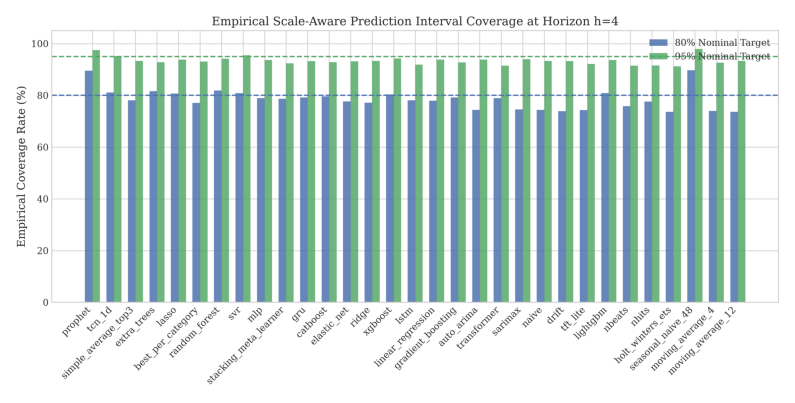

In [3]:
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.image as mpimg

fig_path = Path("results/figures/interval_coverage_h4.png")
if fig_path.exists():
    img = mpimg.imread(str(fig_path))
    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.axis('off')
    plt.show()


---
### Research Findings & Plain Language Interpretation
Ensembling and uncertainty findings:
- Scale-aware conformal prediction bounds scale naturally as a percentage of predicted price, guaranteeing valid coverage across cheap leafy greens and expensive dry-zone produce alike.
- Calibration on the dedicated holdout fold ensures zero in-sample calibration leakage.
